# 03 · Showcase: OpenMesh v2 from metadata to rain

A walk through the OpenMesh v2 record (NYC Mesh links, 2023-10-29 → 2026-11-01) with the weather references around it,
ending with rain rate estimated from the links themselves.

| | |
|---|---|
| **Record** | OpenMesh 2.0.0, Zenodo [10.5281/zenodo.23283445](https://doi.org/10.5281/zenodo.23283445): links, ASOS, METAR, GHCN-Daily, radar |
| **Paper** | Jacoby et al. (2026), ESSD 18, 5817–5836, [10.5194/essd-18-5817-2026](https://doi.org/10.5194/essd-18-5817-2026) |
| **Code** | [`showcase.py`](showcase.py) (all plots and the rain chain) · [`make_showcase.py`](make_showcase.py) (writes this notebook) |
| **Run** | from `tutorials/v2/`; the record is downloaded from Zenodo on the first run (~600 MB) into `dataset/raw/openmesh_v2/` (or set `OPENMESH_V2_DIR`). Needs pycomlink and poligrain; cartopy for the land on the maps (optional). |

Every number here comes from the public record. The gauge next to a path is the nearest ASOS station, often
5–15 km away: a coarse reference for one path, used here to show the method rather than to score it.

**Contents**
- **A · The record:** files, variables, metadata, which signal exists when
- **B · Three years at a glance:** sensors on the map, bands, coverage, growth, the raw level over three years
- **C · What rain does to the links:** a rain week, two rain days, 60 vs 5 GHz on one path
- **D · Rain rate from the links:** the processing chain step by step, then every link against ASOS and the radar
- **E · The reference sensors:** GHCN-Daily vs ASOS, METAR weather, the radar days

In [1]:
import showcase as S
from IPython.display import display
S.style()
R = S.load()          # the v2 record (analysis.datasets, v2); downloaded from Zenodo when missing

---
# A · The record
## A1 · Sensors and files
One row per sensor type in the record.

In [2]:
S.sensor_table(R)

,file,size,period,step,variables,source
sensor,,,,,,
links,data/links/openmesh_links.nc,372 paths / 758 sublinks,2023-10-29 → 2026-11-01,1 min / 1 h / 6 min,"rsl, rsl_avg, rsl_max (dBm)",Zenodo v2
ASOS,data/weather/asos/openmesh_asos.nc,5 stations,2023-10-29 → 2026-11-01,1 min,"rain, T, RH, wind, precip type",Zenodo v2
METAR,data/weather/metar/openmesh_metar.csv,"5 stations, 152,226 reports",2023-10-29 → 2026-11-01,hourly + specials,"present weather, precip, visibility",Zenodo v2
GHCN-Daily,data/weather/ghcn/ghcn_daily.csv,7 stations,2023-10-29 → 2026-10-31,1 day,"rain, snowfall, snow depth",Zenodo v2
radar,data/weather/radar/*.nc,"10 days (5 rain, 5 snow)",2023-11-22 → 2026-02-23,1 h / 15 min / 10 min,"MRMS QPE, precip flag; KOKX",Zenodo v2


In [3]:
S.file_inventory(R)

,MB
file,
data/links/links_metadata.csv,0.1
data/links/openmesh_links.nc,120.1
data/weather/asos/asos_stations.csv,0.0
data/weather/asos/openmesh_asos.nc,471.3
data/weather/ghcn/ghcn_daily.csv,1.0
data/weather/ghcn/ghcn_stations.csv,0.0
data/weather/metar/openmesh_metar.csv,29.5
data/weather/radar/openmesh_radar_kokx_rain_2023-11-22.nc,0.2
data/weather/radar/openmesh_radar_kokx_rain_2023-12-18.nc,0.3


## A2 · The link file
`openmesh_links.nc` follows the [OpenSense CML convention](https://github.com/OpenSenseAction/OS_data_format_conventions/blob/main/netCDF_CML.adoc):
one `cml_id` per path between two NYC Mesh sites, four `sublink_id` slots per path (one per radio and direction),
and one time axis for all of them.

In [4]:
print(dict(R.links.sizes), f'· time axis {len(R.links.time):,} stamps, {S.span(R.links.time)}')
S.variables_table(R.links)

{'cml_id': 372, 'sublink_id': 4, 'time': 475518} · time axis 475,518 stamps, 2023-10-29 → 2026-11-01


,dims,dtype,long_name,units
name,,,,
time,time,datetime64[ns],time_utc,
cml_id,cml_id,<U3,commercial_microwave_link_identifier,
sublink_id,sublink_id,<U9,sublink_identifier,
site_0_lat,cml_id,float64,site_0_latitude,degrees_in_WGS84_projection
site_0_lon,cml_id,float64,site_0_longitude,degrees_in_WGS84_projection
site_1_lat,cml_id,float64,site_1_latitude,degrees_in_WGS84_projection
site_1_lon,cml_id,float64,site_1_longitude,degrees_in_WGS84_projection
length,cml_id,float64,distance_between_pair_of_antennas,m
frequency,"cml_id, sublink_id",float64,sublink_frequency,MHz


In [5]:
R.links.attrs

{'title': 'OpenMesh: A Continuously Updated Wireless Signal Dataset for Opportunistic Weather Sensing in New York City',
 'file_author': 'Dror Jacoby',
 'institution': 'Columbia University (Wireless and Mobile Networking Lab); NYC Mesh (volunteer non-profit community network); Tel Aviv University (CellEnMon Lab)',
 'date': '2026-11-09 14:58:56',
 'source': "NYC Mesh community wireless network (Ubiquiti radios), polled through the network's UISP API",
 'version': '2.0.0',
 'history': '2026-11-09: converted from the NYC Mesh network-management (UISP) export by the OpenMesh conversion scripts (links/build_links.py)',
 'naming_convention': 'OpenSense-1.0',
 'Conventions': 'OpenSense-CML-v1.0',
 'licence': 'CC BY 4.0 (https://creativecommons.org/licenses/by/4.0/)',
 'reference': 'https://doi.org/10.5194/essd-18-5817-2026',
 'comment': "All timestamps UTC, 2023-10-29 00:00:00 to 2026-11-01 23:54:00. The time axis holds the network's own stamps: one per minute to 2025-04-21 (only 00-01 UTC of

## A3 · Sublinks
`links_metadata.csv` has one row per sublink. `sublink_1` / `sublink_2` carry the path's highest frequency in the two
directions (A: site_0 → site_1, B: back); on the 8 dual-frequency paths `sublink_3` / `sublink_4` carry the second
radio over the same path. Path 4 is one of them: 69.1 GHz and 5.8 GHz between the same two buildings.

In [6]:
display(R.smeta[R.smeta.cml_id == '4'])
R.smeta[['frequency', 'length']].describe().round(0).T

,cml_id,sublink_id,site_0_lat,site_0_lon,site_1_lat,site_1_lon,frequency,length,polarization,direction
7,4,sublink_1,40.86134,-73.90780,40.84388,-73.89303,69120.0,2304.9,vertical,A
8,4,sublink_2,40.84388,-73.89303,40.86134,-73.90780,69120.0,2304.9,vertical,B
9,4,sublink_3,40.86134,-73.90780,40.84388,-73.89303,5770.0,2304.9,vertical,A
10,4,sublink_4,40.84388,-73.89303,40.86134,-73.90780,5770.0,2304.9,vertical,B


,count,mean,std,min,25%,50%,75%,max
frequency,758.0,11239.0,17248.0,5290.0,5550.0,5560.0,5760.0,69120.0
length,758.0,1015.0,852.0,37.0,405.0,771.0,1367.0,4479.0


In [7]:
bands = R.paths.band.value_counts().rename(S.BAND_NAME).rename('paths').to_frame()
bands['sublinks'] = R.smeta.frequency.map(S.D.band_of).value_counts().rename(S.BAND_NAME)
display(bands)
R.paths.bands[R.paths.bands.str.contains('[+]')].value_counts().rename('dual-frequency paths').to_frame()

,paths,sublinks
band,,
5 GHz,332,678
60 GHz band (58–69 GHz),34,66
24 GHz,6,14


,dual-frequency paths
bands,
V60+C5,6
V60+K24,1
K24+C5,1


## A4 · Which signal exists when
The network changed what it stores three times, so the file has three signals:
`rsl` (one instantaneous value per minute) to 2025-04-21, then `rsl_avg` and `rsl_max` over each polling window
(1 h, later 6 min). From 2024-07-15 to 2025-04-21 only the hour 00–01 UTC of each day was kept.
Table: million values per signal, band and year.

In [8]:
S.values_per_year(R).rename(columns=str)

2023    2024   2025   2026
variable band                             
rsl      C5    37.83  170.73   3.99   0.00
         K24    0.36    1.22   0.05   0.00
         V60    1.39    6.69   0.25   0.00
rsl_avg  C5     0.00    0.00  13.21  46.26
         K24    0.00    0.00   0.22   0.89
         V60    0.00    0.00   1.02   4.01
rsl_max  C5     0.00    5.20  17.22  46.26
         K24    0.00    0.06   0.27   0.90
         V60    0.00    0.30   1.27   4.01

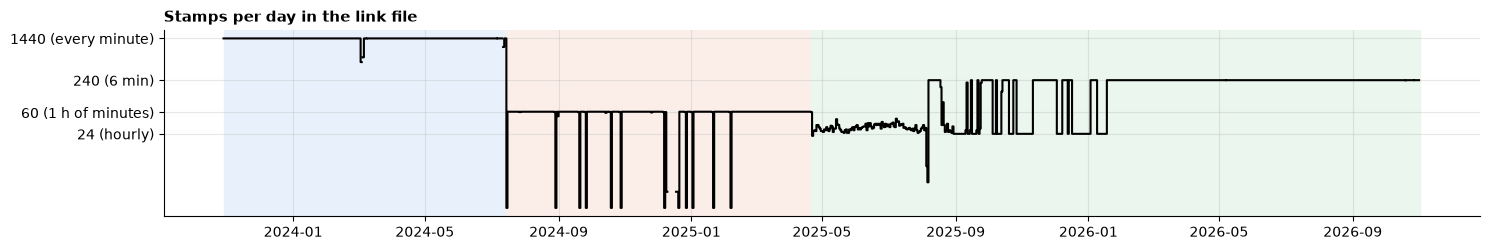

In [9]:
S.stamps_per_day(R);

## A5 · The reference files

In [10]:
display(R.asos_st)
display(S.variables_table(R.asos).loc[list(R.asos.data_vars)])
display(R.ghcn_st)
print('METAR columns:', ', '.join(R.metar.columns))
R.radar_ev[['day', 'kind', 'asos_median_mm', 'radar_mean_mm', 'radar_max_mm']]

,Station ID,Latitude,Longitude,Elevation,Description
0,EWR,40.6925,-74.1687,2.0,"Newark Liberty International Airport (KEWR), NJ ASOS"
1,JFK,40.6386,-73.7622,7.0,"John F. Kennedy International Airport (KJFK), NY ASOS"
2,LGA,40.7794,-73.8803,9.0,"LaGuardia Airport (KLGA), NY ASOS"
3,NYC,40.7790,-73.9690,27.0,"New York City, Central Park (KNYC), NY ASOS"
4,TEB,40.8500,-74.0608,2.0,"Teterboro Airport (KTEB), NJ ASOS"


,dims,dtype,long_name,units
name,,,,
rainfall_amount,"id, time",float32,rainfall_amount_per_time_unit,mm
rainfall_flag,"id, time",int8,rainfall_plausibility_flag,
temperature,"id, time",float32,air_temperature,degrees_celsius
dew_point,"id, time",float32,dew_point_temperature,degrees_celsius
wind_velocity,"id, time",float32,wind_speed,ms-1
wind_direction,"id, time",float32,wind_direction,degrees
wind_gust,"id, time",float32,wind_gust_speed,ms-1
relative_humidity,"id, time",float32,relative_humidity,%
precip_category,"id, time",<U7,precipitation_category,


,ghcn_id,asos_id,network,name,lat,lon,elev
0,US1NJBG0018,NaN,CoCoRaHS,"PALISADES PARK 0.2 WNW, NJ US",40.848094,-74.000247,21.3
1,US1NJHD0023,NaN,CoCoRaHS,"JERSEY CITY 1.6 NNE, NJ US",40.732550,-74.050980,30.2
2,US1NYQN0033,NaN,CoCoRaHS,"HOWARD BEACH 0.4 NNW, NY US",40.662099,-73.841345,2.1
3,USW00014732,LGA,NWS first-order,"LAGUARDIA AIRPORT, NY US",40.779450,-73.880270,3.0
4,USW00014734,EWR,NWS first-order,"NEWARK LIBERTY INTERNATIONAL AIRPORT, NJ US",40.682750,-74.169270,1.9
5,USW00094728,NYC,NWS first-order,"NY CITY CENTRAL PARK, NY US",40.778980,-73.969250,42.7
6,USW00094789,JFK,NWS first-order,"JFK INTERNATIONAL AIRPORT, NY US",40.639150,-73.763900,2.7


METAR columns: station, time, report_type, temperature, dew_point, wind_direction, wind_velocity, wind_gust, precip_amount, precip_trace, present_weather, visibility, altimeter, sea_level_pressure, sky_cover_1, sky_cover_2, sky_cover_3, sky_cover_4, sky_base_1, sky_base_2, sky_base_3, sky_base_4, ice_accretion_1h, ice_accretion_3h, ice_accretion_6h, peak_wind_gust, peak_wind_direction, peak_wind_time, snow_depth, metar


,day,kind,asos_median_mm,radar_mean_mm,radar_max_mm
0,2023-11-22,rain,39.12,38.3,55.3
1,2023-12-18,rain,69.34,66.4,96.7
2,2024-03-10,rain,36.07,34.3,48.8
3,2024-03-23,rain,85.85,72.0,96.6
4,2025-10-30,rain,45.97,49.5,76.9
5,2024-02-13,snow,16.51,17.3,29.7
6,2025-12-14,snow,13.21,13.8,20.9
7,2025-12-27,snow,8.76,9.4,16.0
8,2026-01-25,snow,20.96,30.2,42.4
9,2026-02-23,snow,9.40,43.2,53.6


---
# B · Three years at a glance
## B1 · Every sensor on the map
5 GHz paths (grey) are the bulk of the network; the 24 GHz (orange) and 60 GHz (magenta) paths are the rain-sensitive ones.

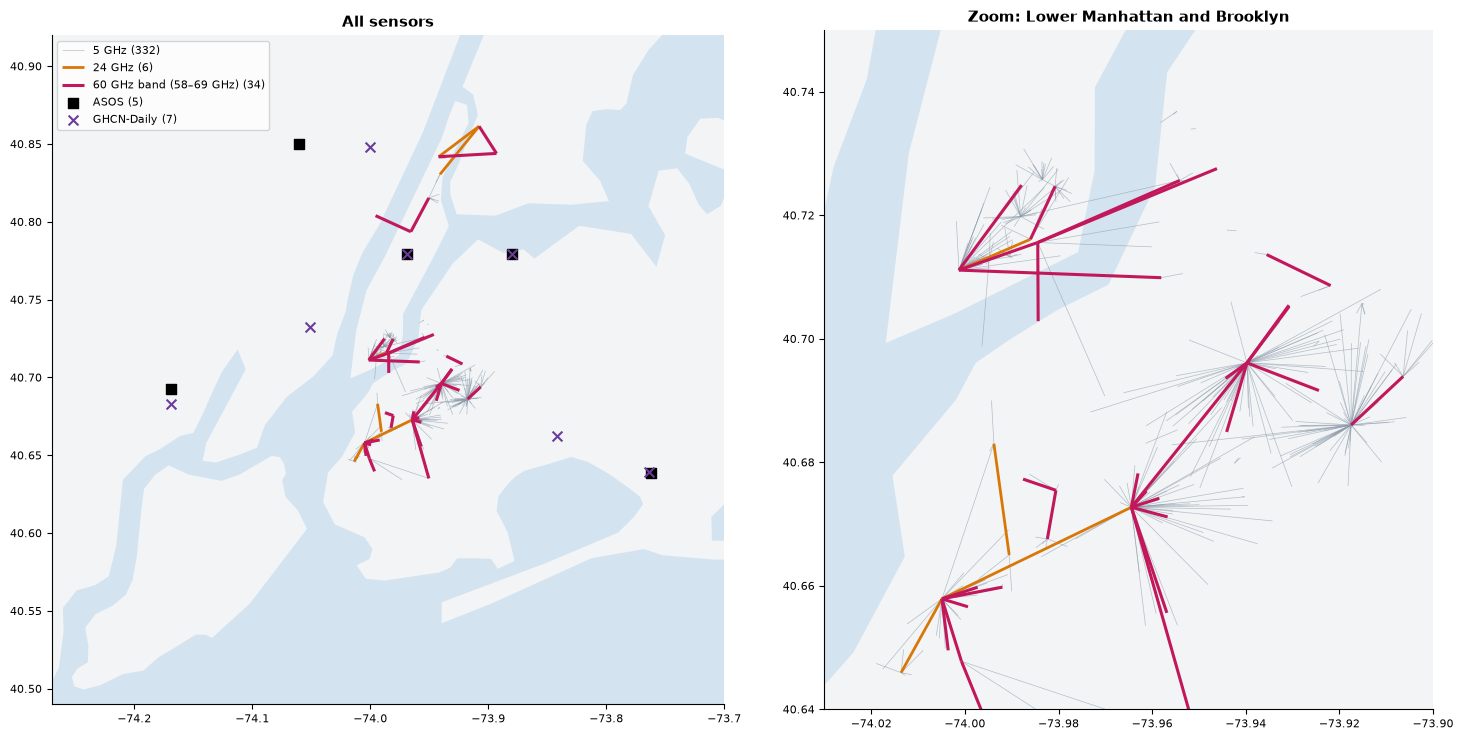

In [11]:
S.sensor_map(R);

## B2 · Bands, carriers and lengths

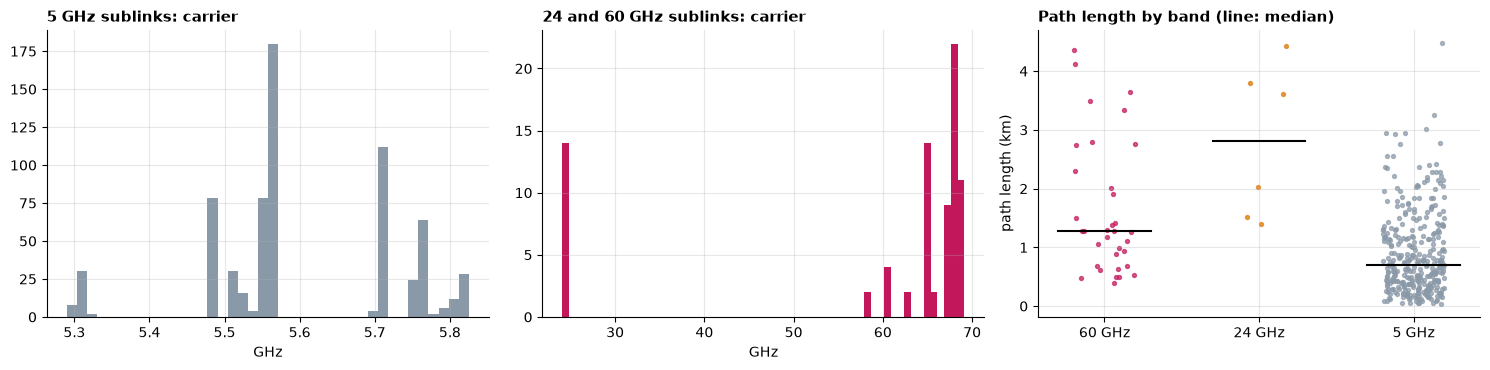

In [12]:
S.band_figure(R);

In [13]:
R.paths[R.paths.band != 'C5'].sort_values('frequency', ascending=False)[
    ['frequency', 'length', 'bands', 'site_0_lat', 'site_0_lon', 'site_1_lat', 'site_1_lon']].round(4)

,frequency,length,bands,site_0_lat,site_0_lon,site_1_lat,site_1_lon
cml_id,,,,,,,
1,69120.0,1901.5588,V60+C5,40.7111,-74.0013,40.7249,-73.9879
5,69120.0,3330.6946,V60,40.6727,-73.9644,40.6961,-73.9397
6,69120.0,3645.8296,V60,40.7111,-74.0013,40.7099,-73.9580
2,69120.0,3489.9146,V60,40.7275,-73.9462,40.7156,-73.9844
4,69120.0,2304.8862,V60+C5,40.8613,-73.9078,40.8439,-73.8930
3,69120.0,1503.7947,V60,40.7156,-73.9844,40.7111,-74.0013
7,68040.0,2006.5742,V60,40.6727,-73.9644,40.6556,-73.9569
8,68040.0,490.6577,V60+C5,40.6579,-74.0049,40.6566,-73.9993
9,68040.0,1178.3496,V60,40.6579,-74.0049,40.6478,-74.0007


## B3 · Coverage over time
Paths with any value per day, and gauges with rain data per day. The shading marks the three sampling periods of A4.
The first call reads the whole link file (about a minute); the result is cached in `cache/`.

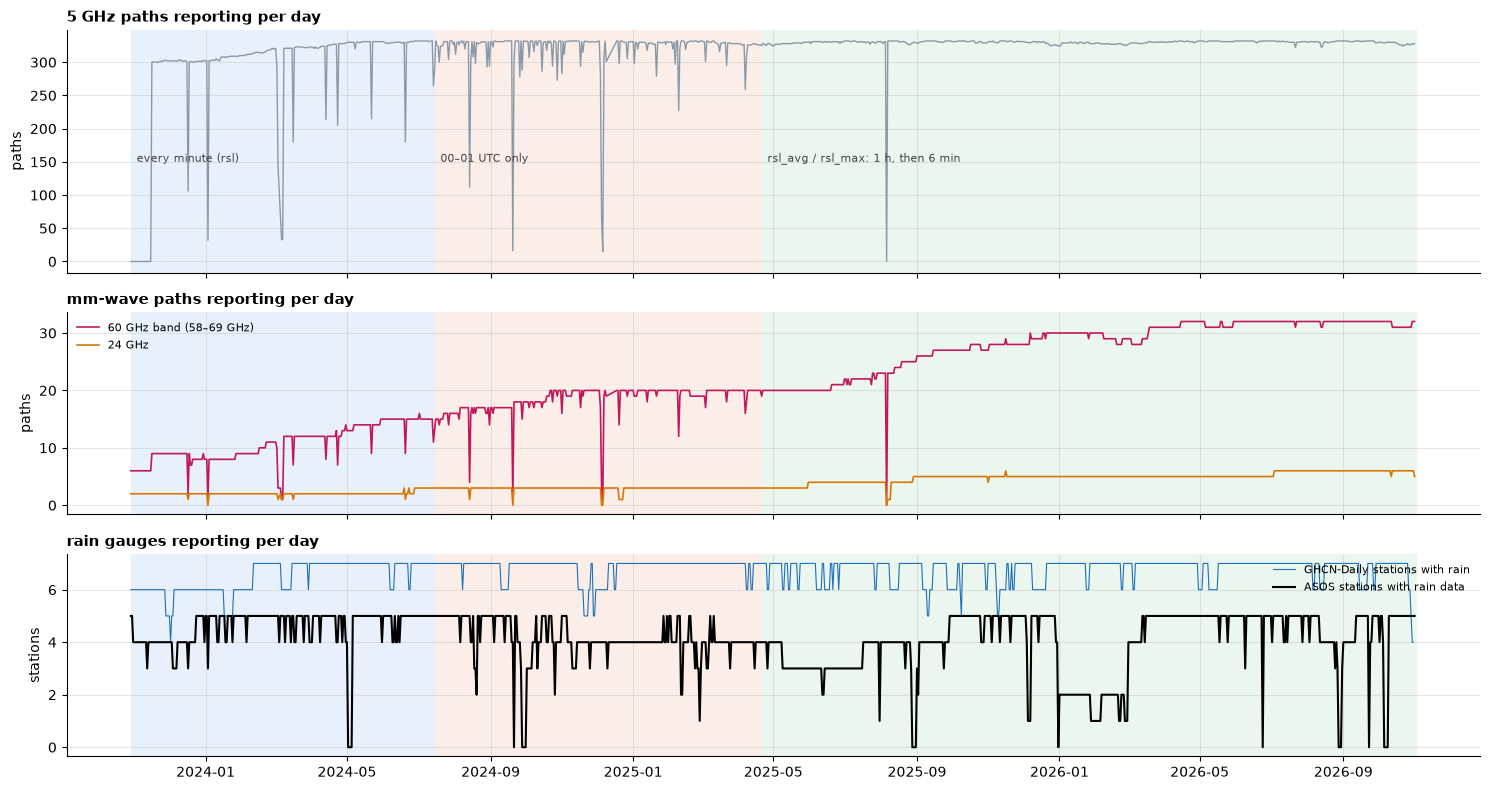

In [14]:
daily = S.paths_reporting_daily(R)
S.coverage_plot(R, daily);

In [15]:
growth = daily.resample('QS').mean().round(0).astype(int)
growth.index = growth.index.to_period('Q').astype(str)
growth.rename(columns=S.BAND_NAME).T

,2023Q4,2024Q1,2024Q2,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2,2026Q3,2026Q4
60 GHz band (58–69 GHz),8,9,13,16,19,20,20,24,28,30,32,32,31
24 GHz,2,2,2,3,3,3,3,4,5,5,5,6,6
5 GHz,214,298,323,319,319,326,328,327,330,329,331,331,328


## B4 · Three years of received level
Daily median and range of `sublink_1` for one path per band (`rsl`, then `rsl_avg`). Steps in the level are
hardware or alignment changes; the deep daily minima of the 60 GHz path are rain.

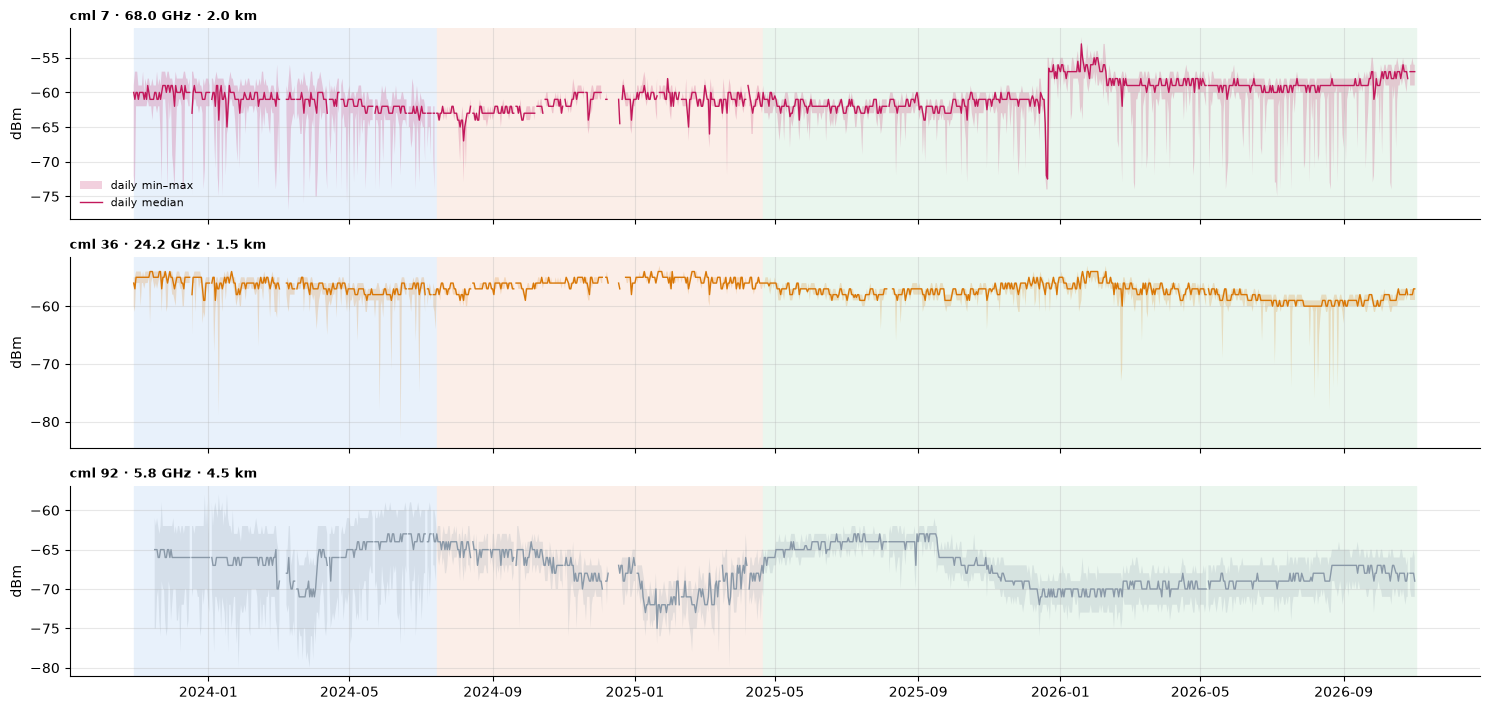

In [16]:
S.three_year_levels(R, {'V60': '7', 'K24': '36', 'C5': '92'});

## B5 · Rain at the ASOS gauges per year

In [17]:
ok = R.asos.rainfall_amount.where(R.asos.rainfall_flag == 0)
display(ok.groupby('time.year').sum(min_count=1).to_pandas().T.round(0).rename_axis('mm per year'))
ok.notnull().groupby('time.year').mean().to_pandas().T.round(2).rename_axis('share of usable minutes')

id,EWR,JFK,LGA,NYC,TEB
mm per year,,,,,
2023,221.0,206.0,263.0,68.0,125.0
2024,547.0,974.0,823.0,992.0,1175.0
2025,473.0,836.0,581.0,847.0,287.0
2026,592.0,494.0,628.0,669.0,797.0


id,EWR,JFK,LGA,NYC,TEB
share of usable minutes,,,,,
2023,0.73,0.85,0.99,0.19,0.71
2024,0.52,0.89,0.76,0.82,0.86
2025,0.45,0.89,0.57,0.78,0.44
2026,0.66,0.65,0.52,0.65,0.79


---
# C · What rain does to the links
## C1 · A rain week at 1-minute resolution
Path 7 (68 GHz, 2 km) in March 2024, both directions, with the nearest ASOS gauge.

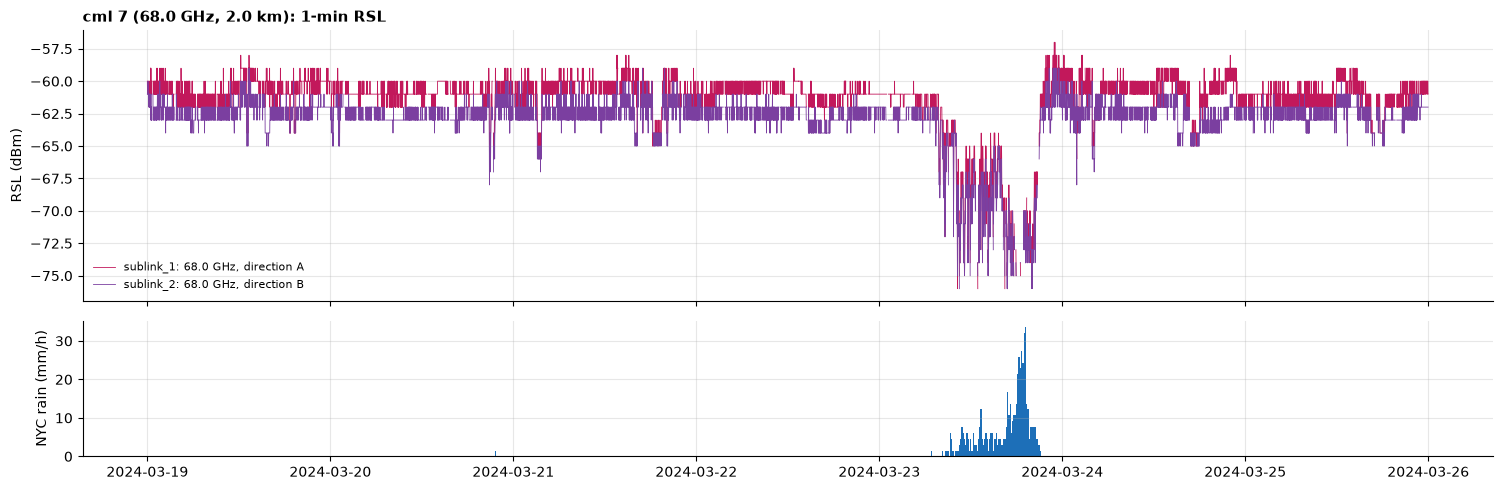

In [18]:
S.rsl_week(R, '7', '2024-03-19', '2024-03-25');

## C2 · The 6-minute era: average and maximum
From 2025-04 each stamp carries the average (`rsl_avg`) and the maximum (`rsl_max`) over the window that ends at it.
In rain the two separate.

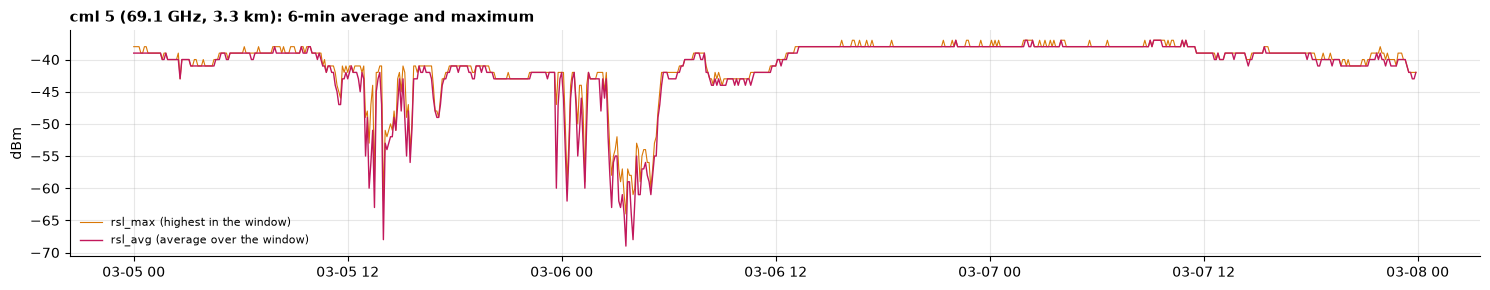

In [19]:
S.avg_max_example(R, '5', '2026-03-05', '2026-03-07');

## C3 · Rain day 2024-03-23 (1-minute data)
The heaviest day of the record (about 86 mm at the ASOS median). Quick look: attenuation is the median level of the
3 days before minus the level. Each panel is one 60 or 24 GHz path; shaded is the 5-min rain rate of the ASOS gauge
nearest its midpoint (named in the title, with its distance).

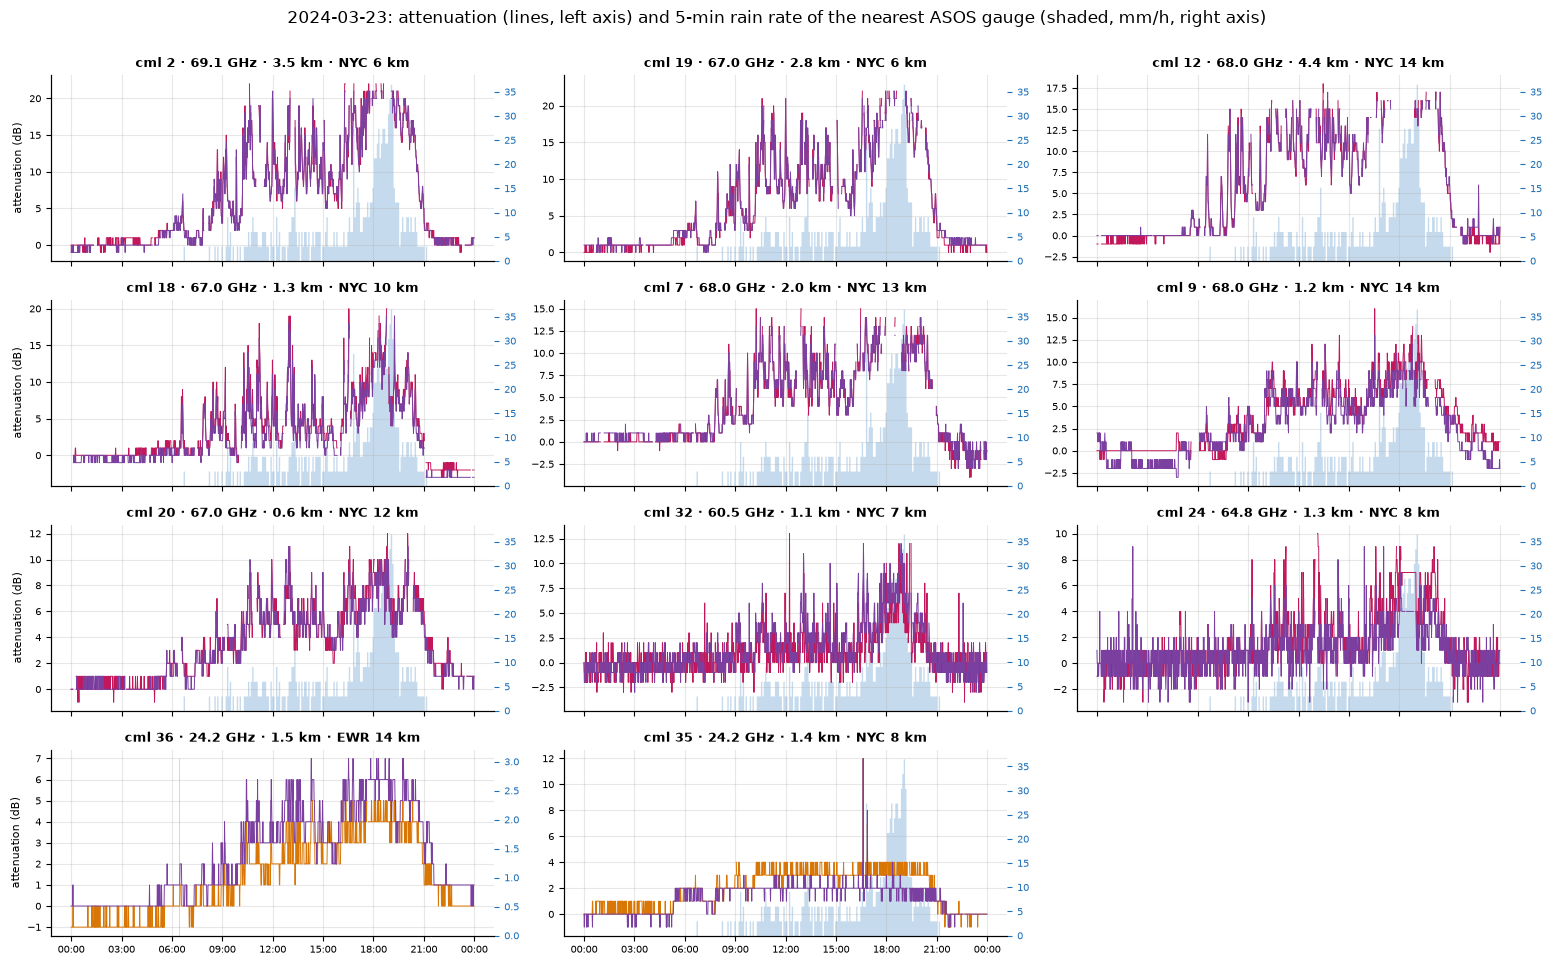

In [20]:
att1 = S.attenuation_vs_prior(R, '2024-03-23')
cids1 = S.mmwave_paths_on(R, att1)
S.event_panels(R, '2024-03-23', att1, cids1);

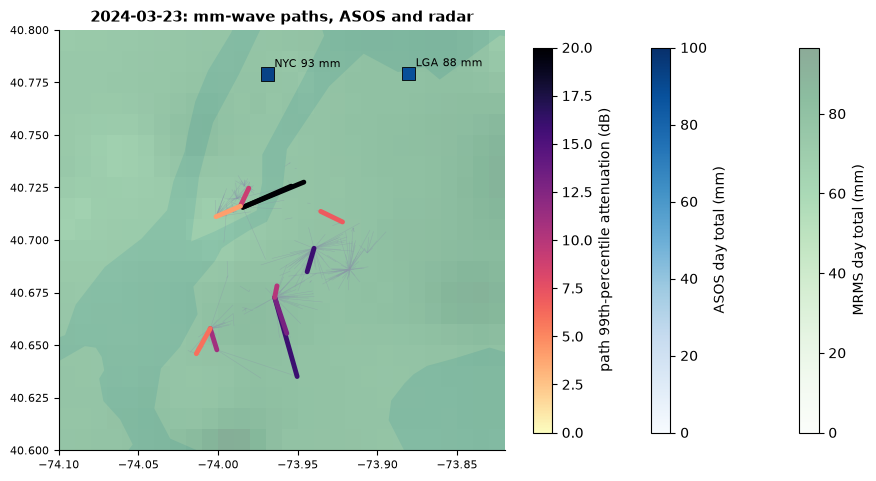

In [21]:
S.event_map(R, '2024-03-23', att1, cids1);

## C4 · Rain day 2026-03-06 (6-minute averages)
Two years later many more 60 GHz paths report.

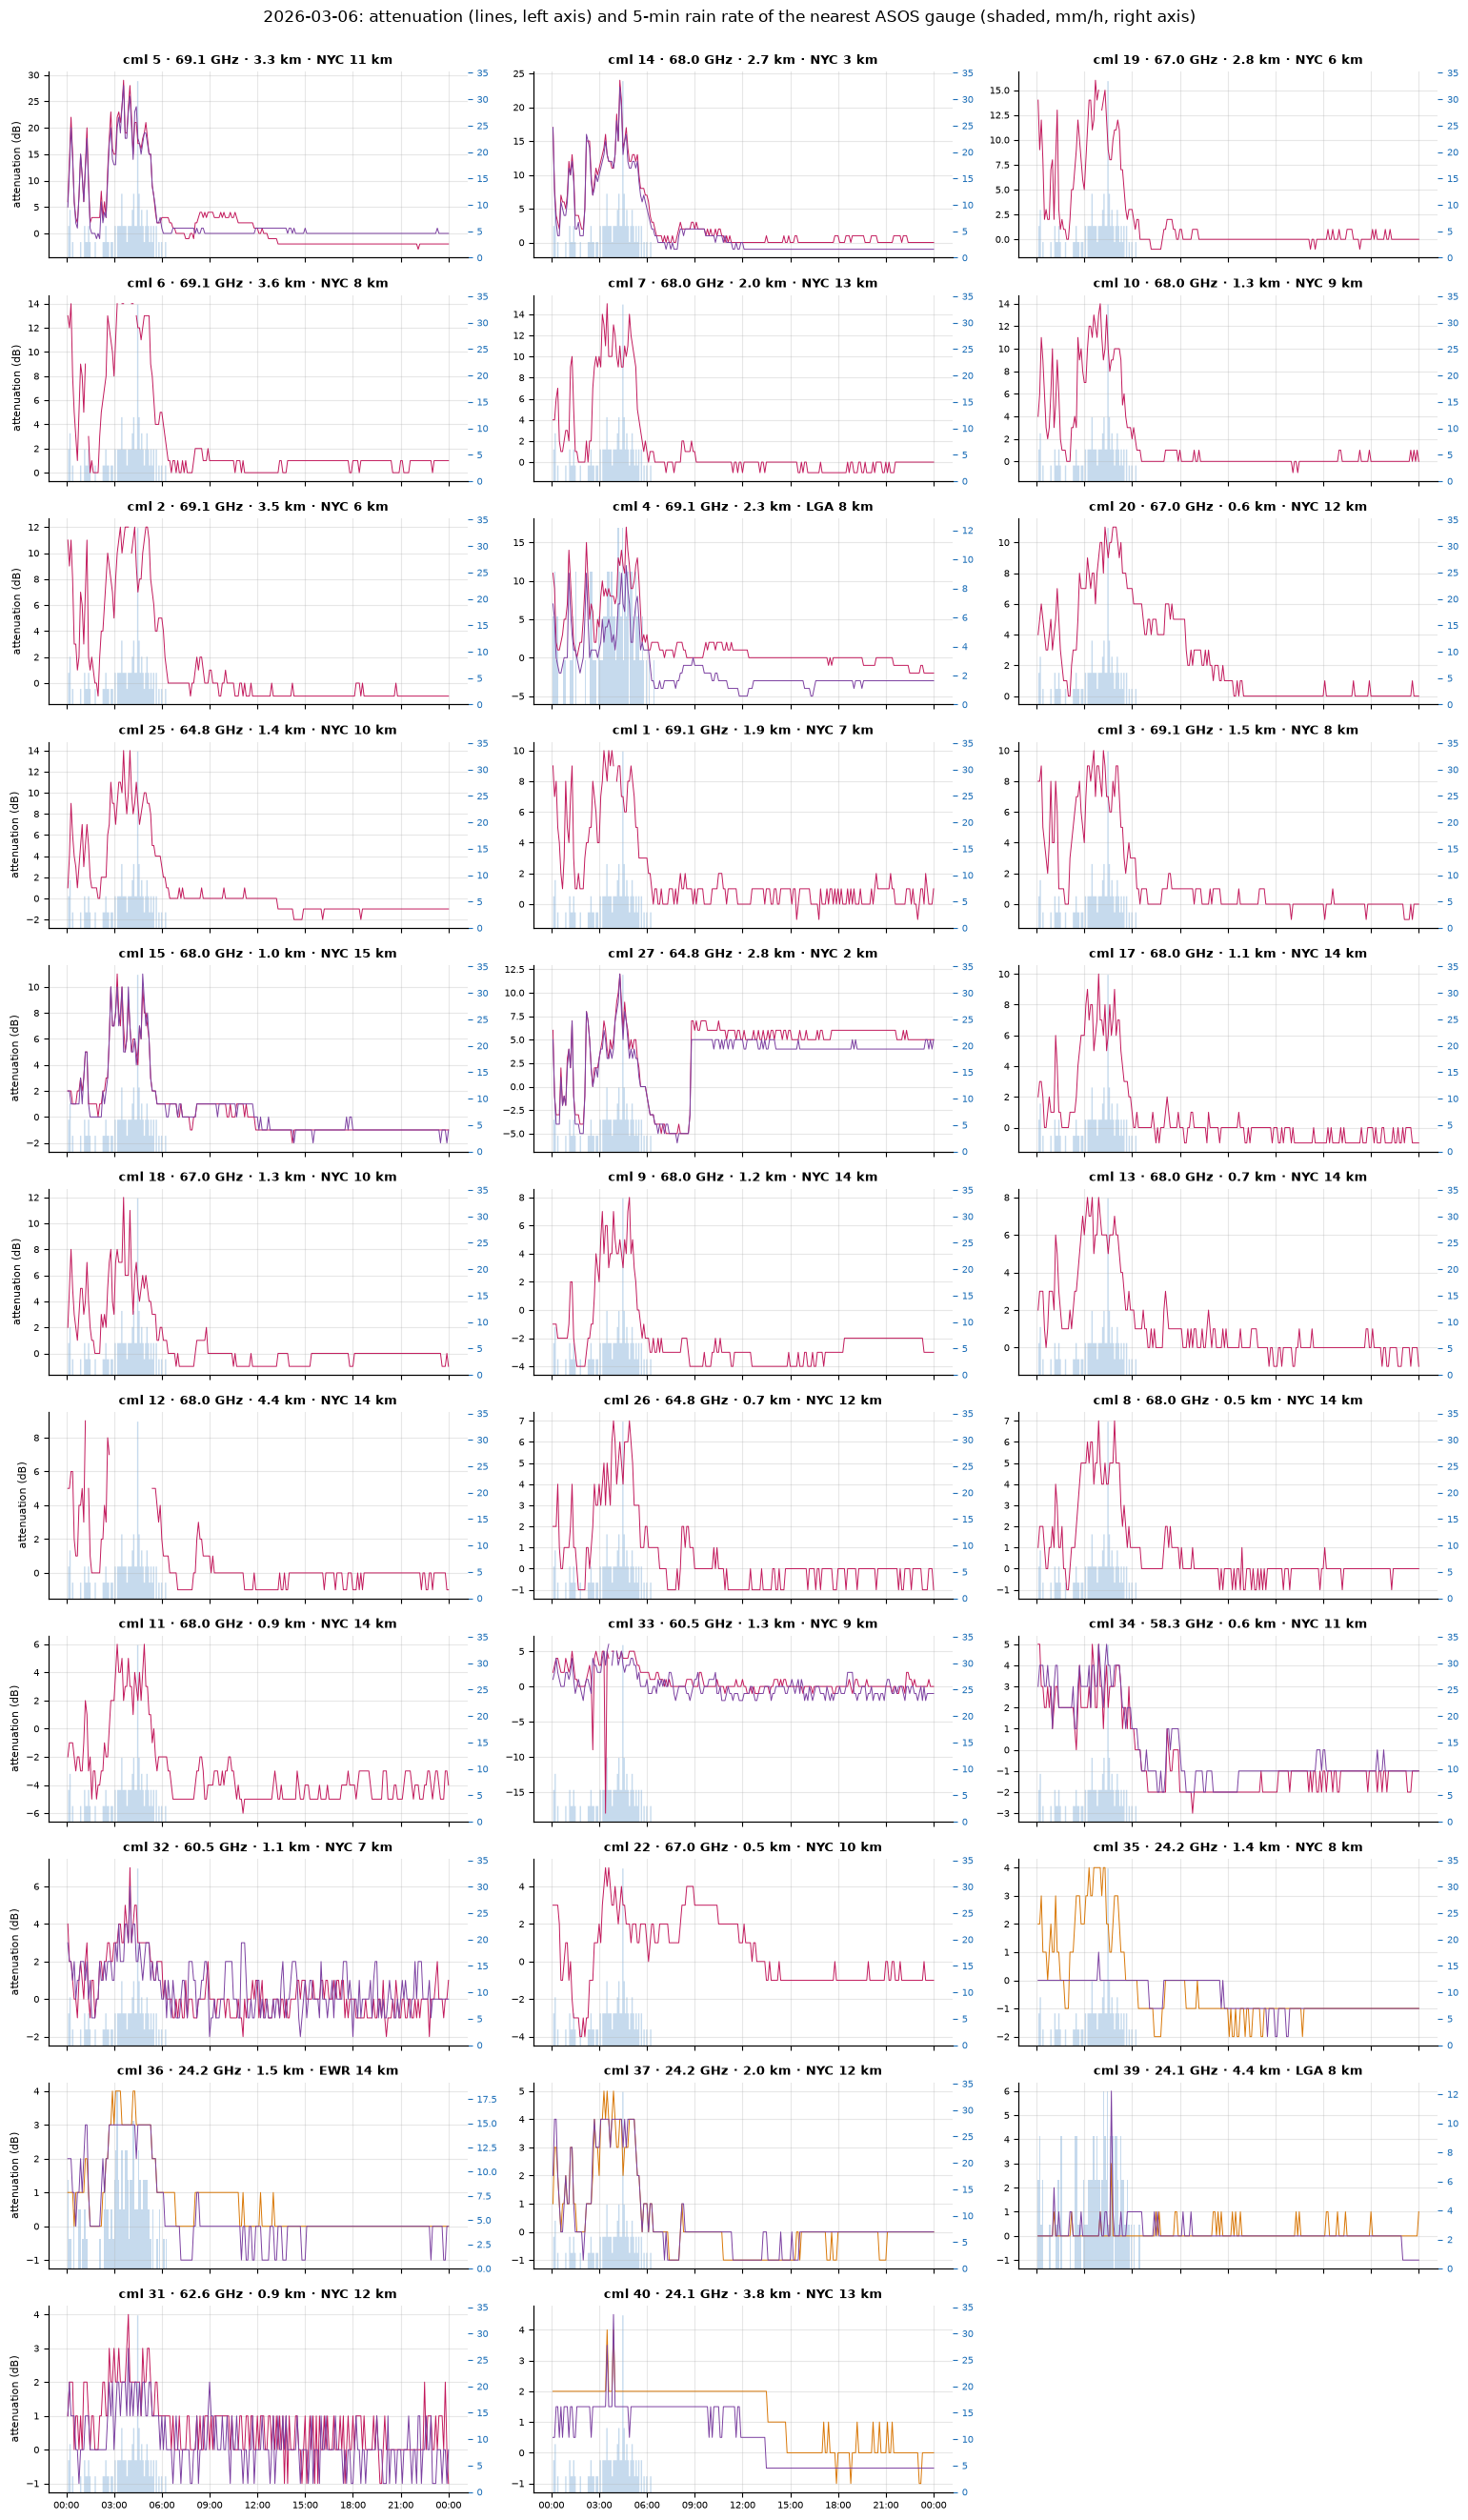

In [22]:
att2 = S.attenuation_vs_prior(R, '2026-03-06')
cids2 = S.mmwave_paths_on(R, att2)
S.event_panels(R, '2026-03-06', att2, cids2);

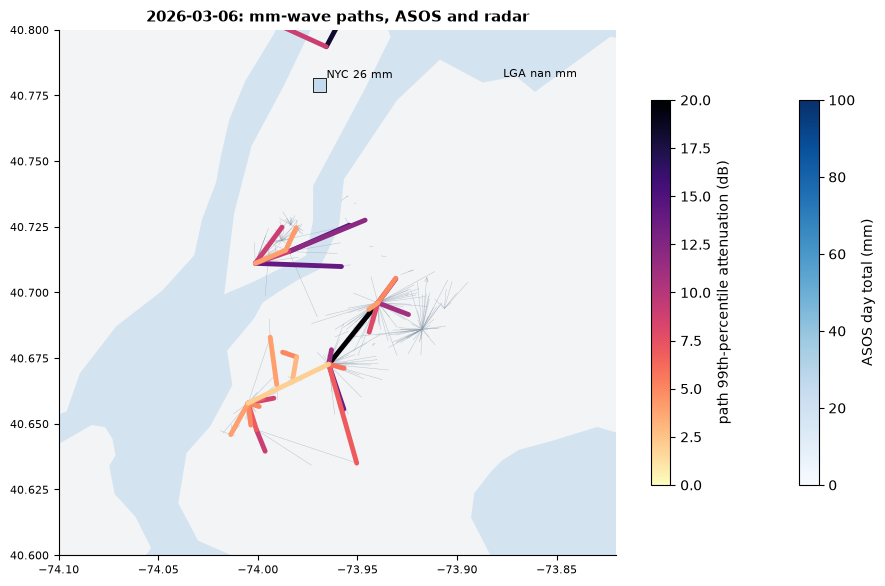

In [23]:
S.event_map(R, '2026-03-06', att2, cids2, radar=False);

## C5 · Same path, two frequencies
On the dual-frequency paths the 60 GHz and the 5 GHz radios see the same rain over the same path.

60 GHz + 5 GHz paths: ['1', '4', '8', '13', '15', '21', '33']


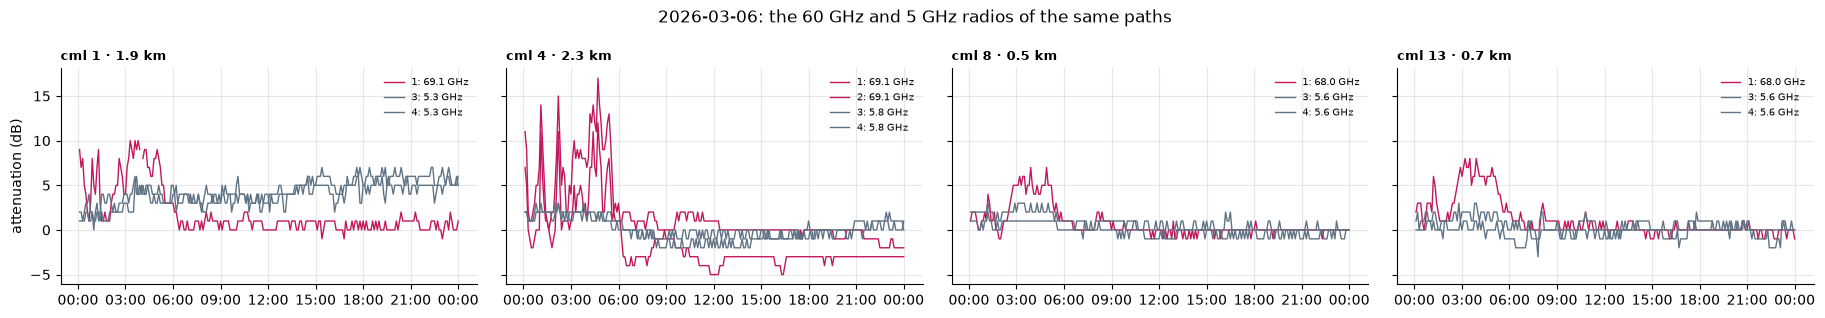

In [24]:
fig, dual = S.dual_frequency(R, '2026-03-06', att2)
print('60 GHz + 5 GHz paths:', dual)

---
# D · Rain rate from the links
## D1 · The processing chain
The standard OpenSense chain, with the [pycomlink](https://github.com/pycomlink/pycomlink) functions for every step
(`S.rain_chain`):

| step | what | function |
|---|---|---|
| 0 | blackout gaps: missing values bounded by levels near the floor are set to the floor (signal lost in heavy rain) | `pycomlink.processing.blackout_gap_detection` |
| 1 | TRSL = −RSL: the record has no transmitted level, so a constant TSL drops out with the baseline | |
| 2 | wet/dry: rolling standard deviation of TRSL over 60 min above 0.8 dB (Schleiss & Berne 2010) | `xarray.rolling().std()` |
| 3 | baseline: the dry level, held constant through each wet period | `pycomlink.processing.baseline.baseline_constant` |
| 4 | observed attenuation A_obs = TRSL − baseline | |
| 5 | wet-antenna attenuation removed: Schleiss et al. 2013 (default), Leijnse et al. 2008, Pastorek et al. 2021 | `pycomlink.processing.wet_antenna` |
| 6 | rain rate R from A with the ITU-R P.838 power law A = k·R^α·L | `pycomlink.processing.k_R_relation.calc_R_from_A` |

The same code runs on 1-min `rsl` and on 6-min `rsl_avg` (windows are set in minutes).
The radar along each path comes from `poligrain` (`GridAtLines`).

## D2 · Step by step on one path: cml 19, 67 GHz, 2.8 km, 2024-03-23

link day total 68.3 mm · ASOS NYC (6 km) 93.0 mm


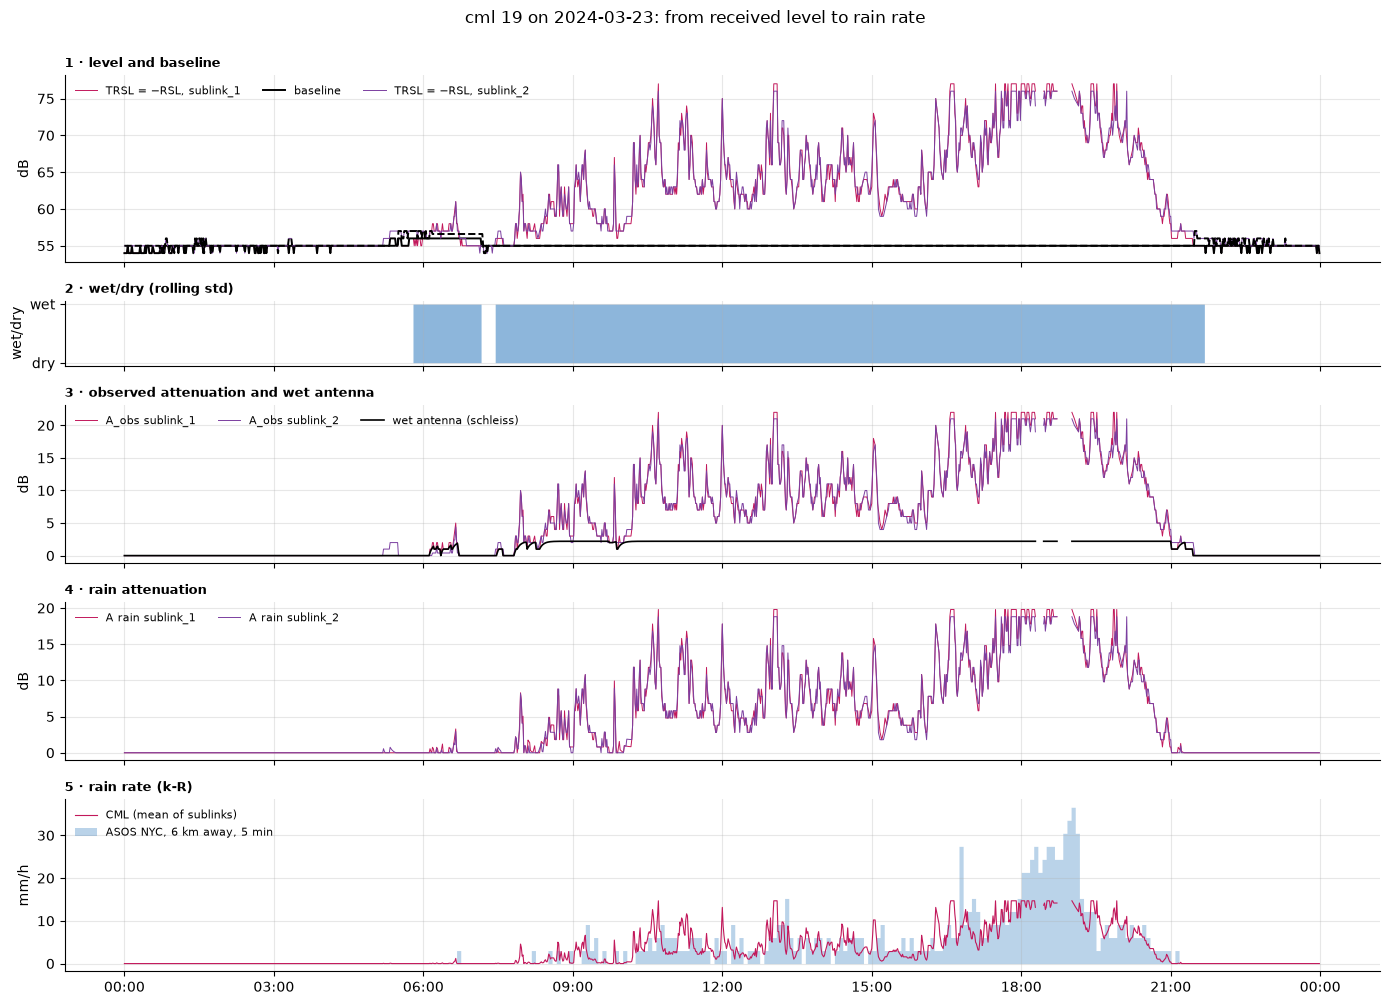

In [25]:
ch = S.rain_chain(R, '19', '2024-03-23')
g19, st19, d19 = S.gauge_day(R, '2024-03-23', '19')
S.chain_panel(ch, g19, 'cml 19 on 2024-03-23: from received level to rain rate', gauge_label=f'ASOS {st19}, {d19:.0f} km away, 5 min');
print(f"link day total {float(ch.R.mean('sublink_id').sum())/60:.1f} mm · ASOS {st19} ({d19:.0f} km) {g19.sum()/12:.1f} mm")

## D3 · Blackouts
In the heaviest rain the 60 GHz signal drops below what the radio reports and the value is missing. Left out, those
minutes count as no rain; filled with the floor they give a lower bound. Minutes filled per path on 2024-03-23:

In [26]:
bo = {c: int(S.rain_chain(R, c, '2024-03-23', sublinks=S.top_sublinks(R, att1, c)).blackout.sum('time').max()) for c in cids1}
S.pd.Series(bo, name='blackout minutes (max over sublinks)').to_frame().T

,2,19,12,18,7,9,20,32,24,36,35
blackout minutes (max over sublinks),41,48,232,7,74,14,10,5,25,2,0


## D4 · Settings against the references
Day totals of every mm-wave path, under six chain settings (wet/dry from the link alone, or from the nearest ASOS
gauge; no wet-antenna correction, Schleiss, Leijnse). `ASOS` is the nearest gauge (`gauge`, `gauge_km`);
`radar` is MRMS averaged along the path (2024-03-23 only). The heatmap and the summary use the radar where there is
one, else ASOS.

In [27]:
SETTINGS = {
    'rsd · no WAA':   dict(wet_method='rsd', waa=None),
    'rsd · Schleiss': dict(wet_method='rsd', waa='schleiss'),
    'rsd · Leijnse':  dict(wet_method='rsd', waa='leijnse'),
    'gauge · no WAA':   dict(wet_method='gauge', waa=None),
    'gauge · Schleiss': dict(wet_method='gauge', waa='schleiss'),
    'gauge · Leijnse':  dict(wet_method='gauge', waa='leijnse'),
}
tables = {d: S.chain_day_totals(R, d, SETTINGS) for d in ['2024-03-23', '2026-03-06']}
display(tables['2024-03-23'])
tables['2026-03-06']

,band,GHz,km,gauge,gauge_km,ASOS,radar,rsd · no WAA,rsd · Schleiss,rsd · Leijnse,gauge · no WAA,gauge · Schleiss,gauge · Leijnse
cml_id,,,,,,,,,,,,,
20,V60,67.0,0.62,NYC,11.5,93.0,77.0,125.3,47.1,46.8,164.1,69.9,68.2
32,V60,60.5,1.05,NYC,6.6,93.0,69.0,58.8,32.2,30.3,79.4,41.5,43.0
9,V60,68.0,1.18,NYC,14.3,93.0,74.8,117.1,67.6,67.5,128.0,73.9,73.9
24,V60,64.8,1.28,NYC,8.3,93.0,73.3,42.6,21.5,20.3,40.8,20.4,20.2
18,V60,67.0,1.30,NYC,10.1,93.0,73.7,116.5,74.8,73.7,115.9,74.5,73.4
35,K24,24.2,1.40,NYC,7.6,93.0,65.8,3.6,2.0,1.1,140.2,15.3,31.1
36,K24,24.2,1.52,EWR,14.2,0.3,74.3,21.7,5.7,4.3,0.5,0.1,0.0
7,V60,68.0,2.01,NYC,12.8,93.0,77.2,84.6,56.1,57.5,91.6,61.9,63.1
19,V60,67.0,2.79,NYC,6.5,93.0,70.4,90.1,68.3,69.5,89.9,68.3,69.5


,band,GHz,km,gauge,gauge_km,ASOS,rsd · no WAA,rsd · Schleiss,rsd · Leijnse,gauge · no WAA,gauge · Schleiss,gauge · Leijnse
cml_id,,,,,,,,,,,,
22,V60,67.0,0.47,NYC,9.6,25.700001,15.6,2.9,4.0,7.9,0.3,1.0
8,V60,68.0,0.49,NYC,13.8,25.700001,13.9,2.8,3.6,70.9,25.3,24.2
34,V60,58.3,0.62,NYC,11.5,25.700001,13.1,0.9,3.5,29.4,4.1,9.9
20,V60,67.0,0.62,NYC,11.5,25.700001,65.9,26.3,27.2,147.6,84.3,76.5
26,V60,64.8,0.68,NYC,11.9,25.700001,28.7,6.0,9.4,48.7,17.5,19.9
13,V60,68.0,0.68,NYC,13.6,25.700001,34.3,13.7,14.0,70.3,30.6,30.2
31,V60,62.6,0.89,NYC,12.0,25.700001,0.7,0.0,0.1,9.2,0.2,1.9
11,V60,68.0,0.93,NYC,14.2,25.700001,30.2,11.7,13.2,49.8,25.3,25.4
15,V60,68.0,0.98,NYC,15.3,25.700001,37.8,20.1,20.1,32.2,16.1,16.5


,2024-03-23 / radar,2026-03-06 / ASOS
median of link / reference,,
rsd · no WAA,1.01,0.89
rsd · Schleiss,0.61,0.45
rsd · Leijnse,0.61,0.52
gauge · no WAA,1.19,1.18
gauge · Schleiss,0.71,0.57
gauge · Leijnse,0.72,0.65


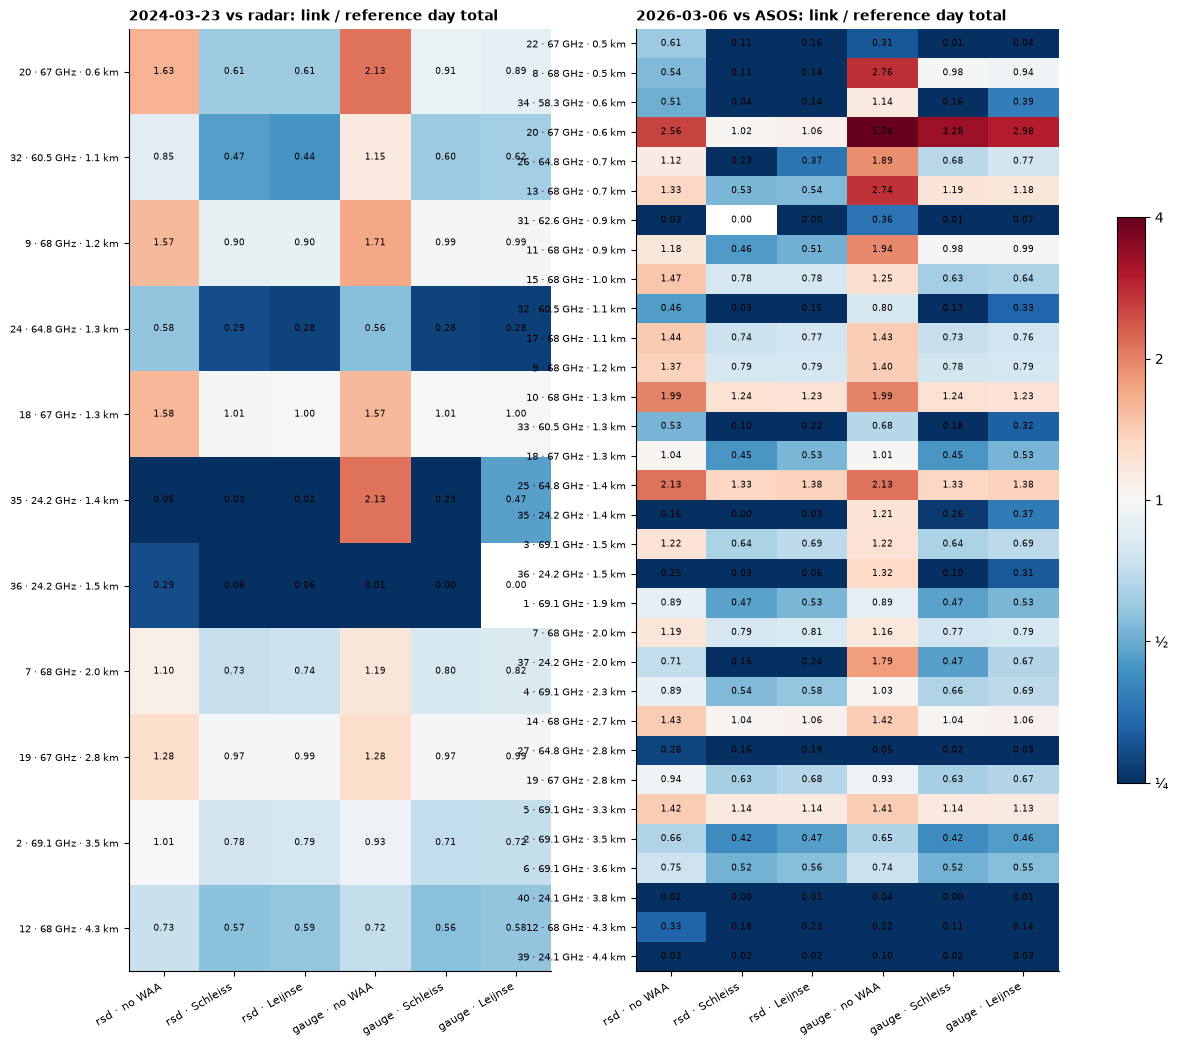

In [28]:
S.ratio_heatmap({'2024-03-23 vs radar': tables['2024-03-23'].assign(ref=tables['2024-03-23'].radar),
                 '2026-03-06 vs ASOS': tables['2026-03-06'].assign(ref=tables['2026-03-06'].ASOS)}, SETTINGS, ref='ref');
summary = S.pd.DataFrame({'2024-03-23 / radar': tables['2024-03-23'][list(SETTINGS)].div(tables['2024-03-23'].radar, axis=0).median(),
                          '2026-03-06 / ASOS': tables['2026-03-06'][list(SETTINGS)].div(tables['2026-03-06'].ASOS, axis=0).median()}).round(2)
summary.rename_axis('median of link / reference')

Reading the table:
- **2024-03-23 against the radar:** with no wet-antenna correction the median path matches MRMS (ratio about 1.0);
  with the Schleiss or Leijnse defaults it comes out about 0.6–0.7. Paths of 1.2–2.8 km (9, 18, 19) land within
  about 10 % of the radar under the Schleiss setting.
- **Short paths (under ~1.1 km, e.g. 20 and 32):** the wet-antenna term is a large share of the attenuation, so the
  choice of model changes the day total by a factor of 2–3.
- **Long paths in heavy rain:** cml 12 (4.4 km) sits at its floor for about 230 minutes (D3); the attenuation is
  capped and the total is low.
- **24 GHz:** the attenuation rises slowly, so the rolling-std flag misses most of it (cml 35: 2–4 mm against 66 mm of
  radar); the gauge-based flag recovers part of it, but only when the gauge itself has data (cml 36's nearest
  gauge, EWR, reports 0.3 mm that day, so its gauge flag stays dry).
- **2026-03-06 (6-min averages):** the only reference is ASOS NYC, about 10 km from most paths, so the spread is
  wide; the shortest paths drop to near zero once the wet antenna is removed.

## D5 · Hour by hour: link, ASOS and radar

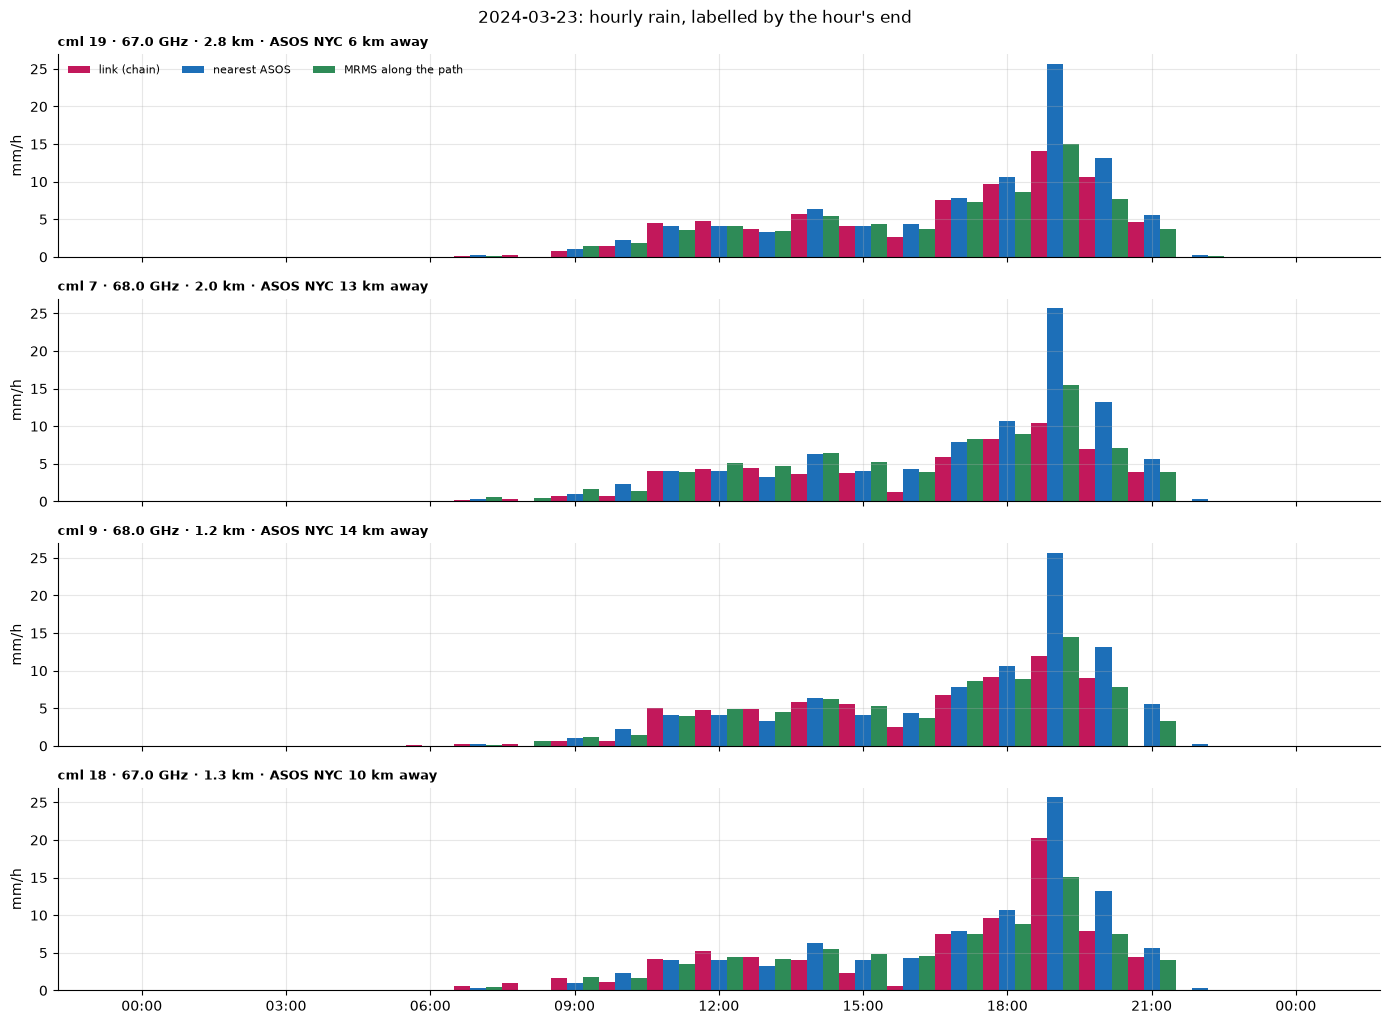

In [29]:
S.hourly_comparison(R, '2024-03-23', ['19', '7', '9', '18']);

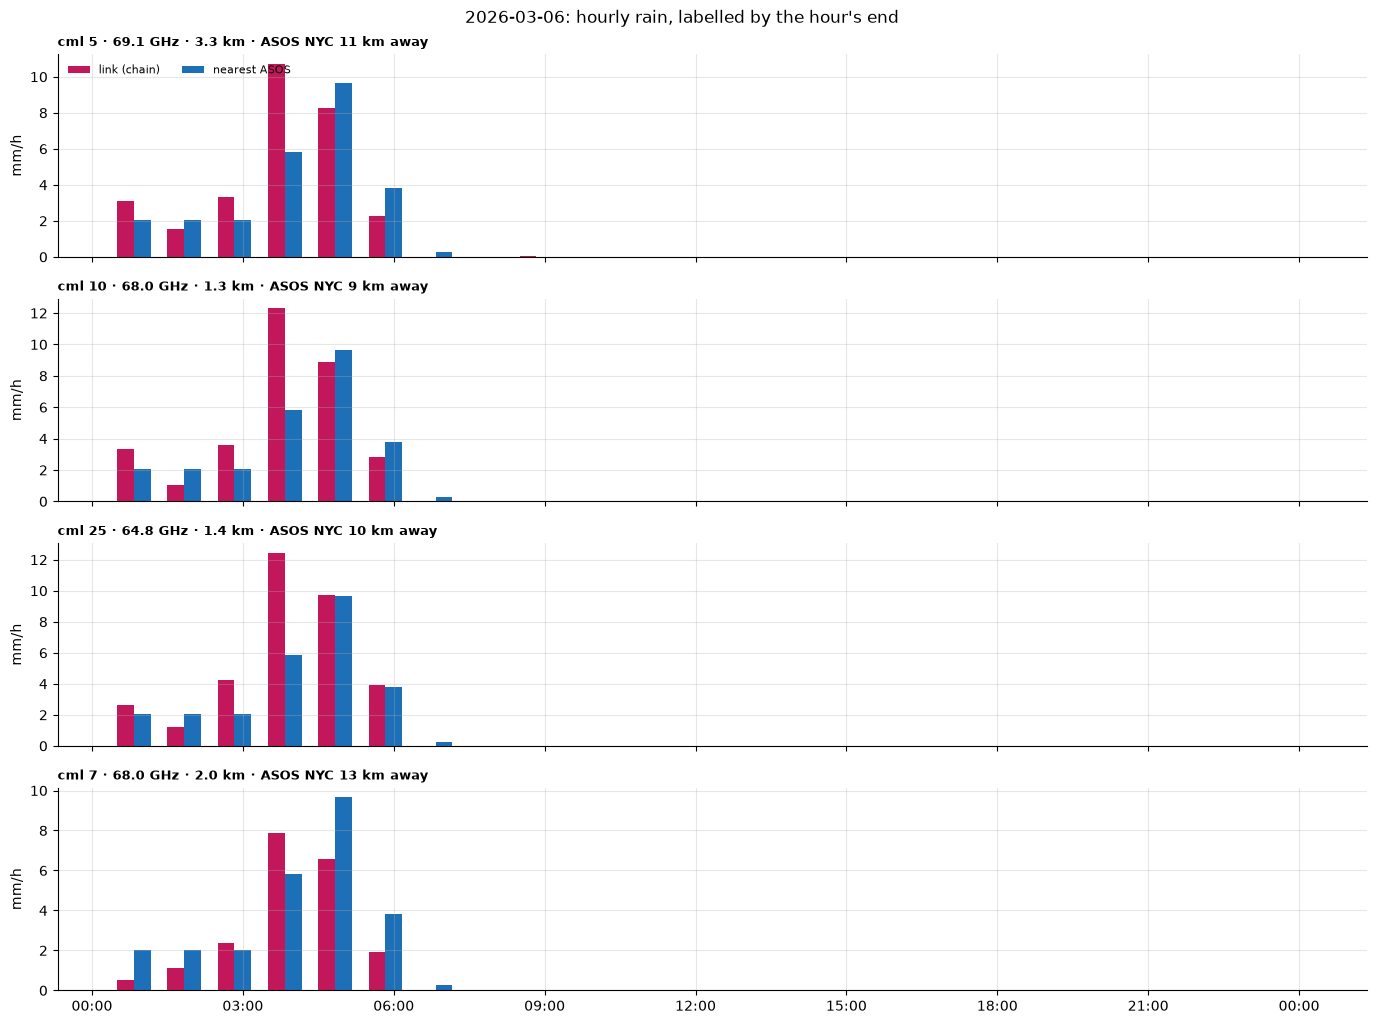

In [30]:
S.hourly_comparison(R, '2026-03-06', ['5', '10', '25', '7']);

## D6 · Attenuation per km against rain rate
Hourly, every 60 GHz path on both days: specific rain attenuation from the chain (after the wet-antenna correction)
against the nearest ASOS gauge, with the ITU-R P.838 curves. The gauge is kilometres from the path, so expect scatter.

856 path-hours · Spearman correlation 0.82


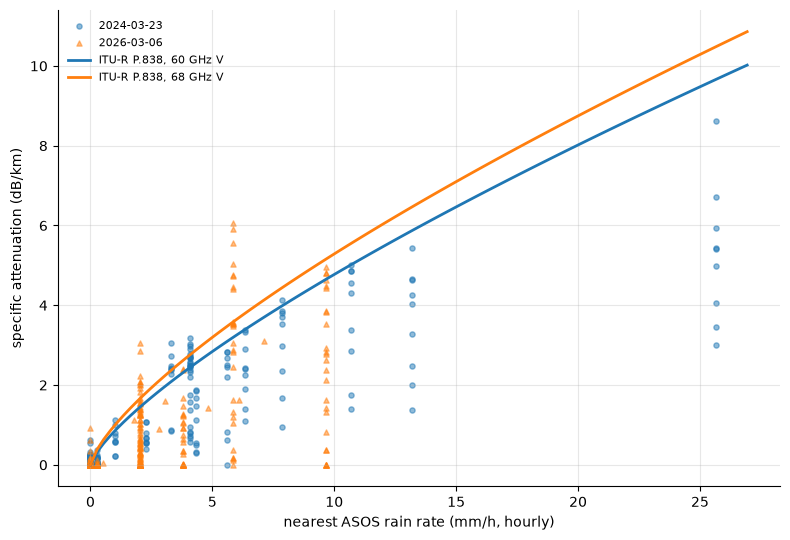

In [31]:
H = S.gamma_vs_rain(R, ['2024-03-23', '2026-03-06'])
print(f"{len(H)} path-hours · Spearman correlation {H[['R', 'gamma']].corr('spearman').iloc[0, 1]:.2f}")

---
# E · The reference sensors
## E1 · GHCN-Daily against ASOS
GHCN-Daily (CoCoRaHS volunteers and COOP gauges) reports days that end in the morning local time, ASOS here UTC
days: single days scatter, months agree.

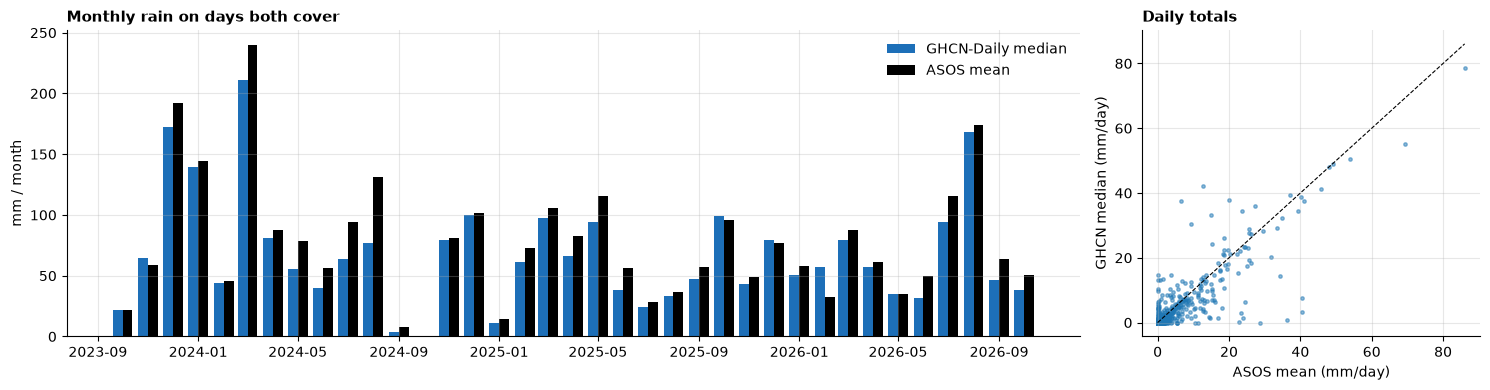

In [32]:
S.reference_monthly(R);

## E2 · METAR: what the observers reported

In [33]:
wx = R.metar.present_weather.fillna('').str.split().explode()
codes = wx.str.replace(r'^[+-]|VC', '', regex=True).replace('', S.np.nan).dropna()
codes.value_counts().head(12).rename('reports').to_frame().T

present_weather,BR,RA,SN,DZ,HZ,TSRA,FG,TS,MIFG,FU,FZFG,BLSN
reports,18264,16181,2751,2378,1013,912,802,457,406,288,248,123


## E3 · The 10 radar days

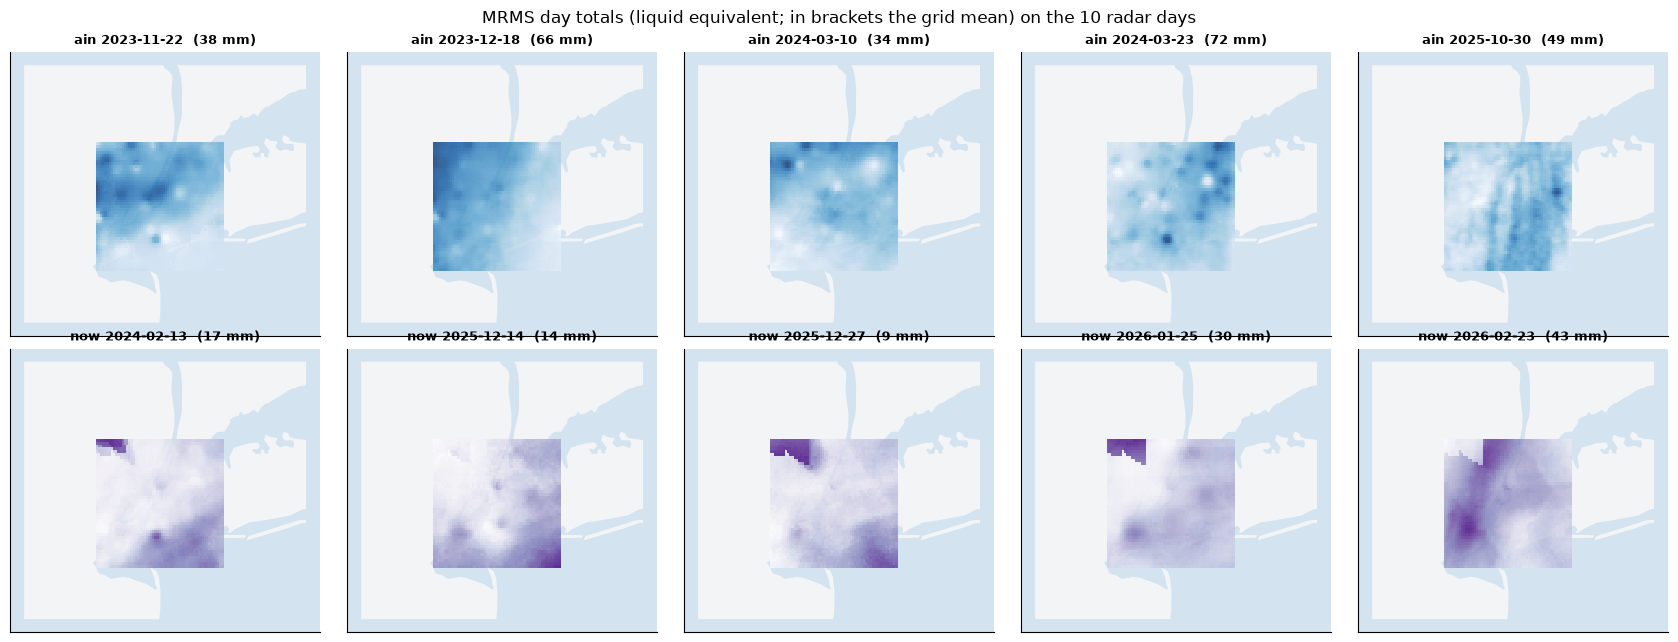

In [34]:
S.radar_days_grid(R);

---
**More:** [00_quickstart](00_quickstart.ipynb) (open the files with plain xarray) · [01_data_overview](01_data_overview.ipynb)
· [02_analysis](02_analysis.ipynb) (rain over all 10 radar days) · file formats in [`dataset/formats/`](../../dataset/formats/)
· every file in [`DETAILS.md`](../../DETAILS.md).